In [1]:
!pip install -q wfdb

In [2]:
import os, time, numpy as np, wfdb
from scipy.signal import butter, filtfilt
from google.colab import drive
drive.mount('/content/drive')
SAVE = '/content/drive/MyDrive/ecg-project'
RAW = f'{SAVE}/mitdb'
os.makedirs(RAW, exist_ok=True)

Mounted at /content/drive


In [3]:
DS1 = ["101","106","108","109","112","114","115","116","118","119","122",
       "124","201","203","205","207","208","209","215","220","223","230"]
DS2 = ["100","103","105","111","113","117","121","123","200","202","210",
       "212","213","214","219","221","222","228","231","232","233","234"]

def have(rec):
    dat, atr = f'{RAW}/{rec}.dat', f'{RAW}/{rec}.atr'
    return os.path.exists(dat) and os.path.getsize(dat) > 1_000_000 and os.path.exists(atr)

def download(rec, tries=5):
    if have(rec): return True
    for t in range(tries):
        try:
            wfdb.dl_database('mitdb', dl_dir=RAW, records=[rec])
            if have(rec): return True
        except Exception as e:
            print(f'\n{rec} retry {t+1}: {type(e).__name__}'); time.sleep(5 * (t + 1))
    return False

failed = []
for r in DS1 + DS2:
    ok = download(r); print(r, 'ok' if ok else 'FAILED', end=' | ', flush=True)
    if not ok: failed.append(r)
print('\nfailed:', failed)

101 ok | 106 ok | 108 ok | 109 ok | 112 ok | 114 ok | 115 ok | 116 ok | 118 ok | 119 ok | 122 ok | 124 ok | 201 ok | 203 ok | 205 ok | 207 ok | 208 ok | 209 ok | 215 ok | 220 ok | 223 ok | 230 ok | 100 ok | 103 ok | 105 ok | 111 ok | 113 ok | 117 ok | 121 ok | 123 ok | 200 ok | 202 ok | 210 ok | 212 ok | 213 ok | 214 ok | 219 ok | 221 ok | 222 ok | 228 ok | 231 ok | 232 ok | 233 ok | 234 ok | 
failed: []


In [4]:
AAMI = {"N":"N","L":"N","R":"N","e":"N","j":"N",
        "A":"S","a":"S","J":"S","S":"S",
        "V":"V","E":"V","F":"F","/":"Q","f":"Q","Q":"Q"}
b, a = butter(3, [0.5, 40], btype="band", fs=360)
PRE, POST = 90, 162          # 0.25 s before, 0.45 s after the R-peak

def get_signal(rec):
    sig = wfdb.rdrecord(f'{RAW}/{rec}').p_signal[:, 0]
    sig = filtfilt(b, a, sig)
    return (sig - sig.mean()) / sig.std()

def load_record(rec):
    sig = get_signal(rec)
    ann = wfdb.rdann(f'{RAW}/{rec}', 'atr')
    keep = [(p, AAMI[s]) for p, s in zip(ann.sample, ann.symbol) if s in AAMI]
    peaks = np.array([p for p, _ in keep]); labels = np.array([l for _, l in keep])
    n = len(peaks)
    dd = np.diff(peaks) / 360
    pre = np.r_[dd[0], dd]; post = np.r_[dd, dd[-1]]
    local = np.array([pre[max(0, i-10):i].mean() if i > 0 else pre[0] for i in range(n)])
    feats = np.stack([pre, post, np.full(n, pre.mean()), local, pre/local, post/local], axis=1)
    ok = (peaks >= PRE) & (peaks < len(sig) - POST)
    X = np.stack([sig[p-PRE:p+POST] for p in peaks[ok]])
    return X, feats[ok], labels[ok], peaks[ok]

def build(records):
    Xs, rs, ys, ids, pks = [], [], [], [], []
    for r in records:
        X, rr, y, pk = load_record(r)
        Xs.append(X); rs.append(rr); ys.append(y); pks.append(pk); ids.append(np.full(len(y), r))
    return [np.concatenate(v) for v in (Xs, rs, ys, ids, pks)]

CACHE = f'{SAVE}/data_final.npz'
if os.path.exists(CACHE):
    d = np.load(CACHE); print('loaded cache')
    X1, rr1, y1, id1, pk1 = [d[k] for k in ["X1","rr1","y1","id1","pk1"]]
    X2, rr2, y2, id2, pk2 = [d[k] for k in ["X2","rr2","y2","id2","pk2"]]
else:
    X1, rr1, y1, id1, pk1 = build(DS1)
    X2, rr2, y2, id2, pk2 = build(DS2)
    np.savez(CACHE, X1=X1, rr1=rr1, y1=y1, id1=id1, pk1=pk1, X2=X2, rr2=rr2, y2=y2, id2=id2, pk2=pk2)
    print('built and cached')
print(X1.shape, rr1.shape, X2.shape, rr2.shape)

built and cached
(51002, 252) (51002, 6) (49692, 252) (49692, 6)


In [5]:
from collections import Counter
C4 = ["N","S","V","F"]; c2i = {c: i for i, c in enumerate(C4)}
m1, m2 = y1 != "Q", y2 != "Q"
X1_, rr1_, y1_, id1_ = X1[m1], rr1[m1], y1[m1], id1[m1]
X2_, rr2_, y2_, id2_, pk2_ = X2[m2], rr2[m2], y2[m2], id2[m2], pk2[m2]
y1_i = np.array([c2i[c] for c in y1_]); y2_i = np.array([c2i[c] for c in y2_])
print("train DS1:", dict(Counter(y1_))); print("test DS2: ", dict(Counter(y2_)))

train DS1: {np.str_('N'): 45848, np.str_('S'): 944, np.str_('V'): 3788, np.str_('F'): 414}
test DS2:  {np.str_('N'): 44240, np.str_('S'): 1837, np.str_('V'): 3220, np.str_('F'): 388}


In [6]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
def report(yt, yp, title=""):
    print("===", title)
    print(classification_report(yt, yp, labels=[0,1,2,3], target_names=C4, digits=3, zero_division=0))
    print(confusion_matrix(yt, yp, labels=[0,1,2,3]))
    print("macro F1 (N,S,V,F):", round(f1_score(yt, yp, labels=[0,1,2,3], average="macro", zero_division=0), 3))

In [7]:
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import GroupKFold
device = "cuda" if torch.cuda.is_available() else "cpu"; print("device:", device)
tt = lambda a: torch.tensor(a, dtype=torch.float32)

def beat_norm(X):
    X = X - X.mean(1, keepdims=True)
    return X / (X.std(1, keepdims=True) + 1e-8)

class BeatCNN(nn.Module):
    def __init__(self, n_rr, n_cls=4):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(1,16,7,padding=3), nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(16,32,5,padding=2), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32,64,5,padding=2), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64,64,3,padding=1), nn.BatchNorm1d(64), nn.ReLU(), nn.AdaptiveAvgPool1d(1))
        self.fc = nn.Sequential(nn.Linear(64 + n_rr, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, n_cls))
    def forward(self, x, rr):
        return self.fc(torch.cat([self.conv(x).squeeze(-1), rr], dim=1))

def train_cnn(Xa, ra, ya_i, epochs, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    mu, sd = ra.mean(0), ra.std(0) + 1e-8
    nrm = lambda r: ((r - mu) / sd).astype(np.float32)
    cnt = np.bincount(ya_i, minlength=4)
    w = (cnt.sum() / (4 * cnt)) ** 0.5                      # softened class weights
    crit = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32).to(device))
    model = BeatCNN(n_rr=ra.shape[1]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    dl = DataLoader(TensorDataset(tt(Xa).unsqueeze(1), tt(nrm(ra)), torch.tensor(ya_i)),
                    batch_size=256, shuffle=True)
    for _ in range(epochs):
        model.train()
        for xb, rb, yb in dl:
            xb, rb, yb = xb.to(device), rb.to(device), yb.to(device)
            opt.zero_grad(); crit(model(xb, rb), yb).backward(); opt.step()
    return model, nrm

@torch.no_grad()
def predict(model, X, rr_n):
    model.eval(); out = []
    for i in range(0, len(X), 1024):
        out.append(model(tt(X[i:i+1024]).unsqueeze(1).to(device), tt(rr_n[i:i+1024]).to(device)).argmax(1).cpu().numpy())
    return np.concatenate(out)

device: cuda


In [8]:
from sklearn.ensemble import RandomForestClassifier
oof = np.zeros(len(y1_i), dtype=int)
for tr, va in GroupKFold(5).split(rr1_, y1_i, id1_):
    rf = RandomForestClassifier(200, min_samples_leaf=3, class_weight="balanced_subsample",
                                n_jobs=-1, random_state=0).fit(rr1_[tr], y1_i[tr])
    oof[va] = rf.predict(rr1_[va])
print("RF DS1 CV macro F1:", round(f1_score(y1_i, oof, average="macro"), 3))

RF DS1 CV macro F1: 0.338


In [9]:
def cv_oof(X, epochs, seed=0):
    oof = np.zeros(len(y1_i), dtype=int)
    for tr, va in GroupKFold(5).split(X, y1_i, id1_):
        m, nrm = train_cnn(X[tr], rr1_[tr], y1_i[tr], epochs, seed)
        oof[va] = predict(m, X[va], nrm(rr1_[va]))
    return oof

for ep in [5, 10, 15]:
    o = cv_oof(X1_, ep)
    print(ep, "epochs | CV macro F1:", round(f1_score(y1_i, o, average="macro"), 3),
          "| V F1:", round(f1_score(y1_i, o, labels=[2], average=None)[0], 3), flush=True)

5 epochs | CV macro F1: 0.357 | V F1: 0.479
10 epochs | CV macro F1: 0.362 | V F1: 0.43
15 epochs | CV macro F1: 0.427 | V F1: 0.533


In [10]:
BEST_TRY = 10   # your choice from Cell 9
o = cv_oof(beat_norm(X1_), BEST_TRY)
print("per-beat | CV macro F1:", round(f1_score(y1_i, o, average="macro"), 3),
      "| V F1:", round(f1_score(y1_i, o, labels=[2], average=None)[0], 3))

per-beat | CV macro F1: 0.37 | V F1: 0.489


In [17]:
BEST = 15               # from Cell 9
USE_BEAT_NORM = False   # True only if Cell 10 clearly won
XA = beat_norm(X1_) if USE_BEAT_NORM else X1_
XB = beat_norm(X2_) if USE_BEAT_NORM else X2_

rf = RandomForestClassifier(300, min_samples_leaf=3, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=0).fit(rr1_, y1_i)
report(y2_i, rf.predict(rr2_), "RF baseline, DS2")

f1s, vrec, preds = [], [], []
for seed in [0, 1, 2]:
    m, nrm = train_cnn(XA, rr1_, y1_i, BEST, seed)
    p = predict(m, XB, nrm(rr2_)); preds.append(p)
    f1s.append(f1_score(y2_i, p, average="macro"))
    vrec.append(((p == 2) & (y2_i == 2)).sum() / (y2_i == 2).sum())
    print(f"seed {seed}: macro F1 {f1s[-1]:.3f} | V recall {vrec[-1]:.3f}", flush=True)
print(f"CNN macro F1 {np.mean(f1s):.3f} ± {np.std(f1s):.3f} | V recall {np.mean(vrec):.3f} ± {np.std(vrec):.3f}")

pred_final = preds[int(np.argsort(f1s)[1])]          # median seed
report(y2_i, pred_final, "CNN (median seed), DS2")
np.save(f"{SAVE}/pred_final.npy", pred_final)

=== RF baseline, DS2
              precision    recall  f1-score   support

           N      0.966     0.933     0.949     44240
           S      0.072     0.104     0.085      1837
           V      0.457     0.606     0.521      3220
           F      0.000     0.000     0.000       388

    accuracy                          0.874     49685
   macro avg      0.374     0.411     0.389     49685
weighted avg      0.892     0.874     0.882     49685

[[41268  1513  1450     9]
 [  778   191   868     0]
 [  303   962  1952     3]
 [  384     1     3     0]]
macro F1 (N,S,V,F): 0.389
seed 0: macro F1 0.405 | V recall 0.966
seed 1: macro F1 0.474 | V recall 0.982
seed 2: macro F1 0.512 | V recall 0.942
CNN macro F1 0.464 ± 0.044 | V recall 0.963 ± 0.016
=== CNN (median seed), DS2
              precision    recall  f1-score   support

           N      0.986     0.833     0.903     44240
           S      0.243     0.626     0.350      1837
           V      0.480     0.982     0.645    

In [12]:
import pandas as pd
df = pd.DataFrame({"rec": id2_, "true": y2_i, "pred": pred_final})
v = df[df.true == 2].assign(hit=lambda d: d.pred == 2).groupby("rec").hit.agg(["mean", "size"])
print(v.round(2))
print("median V recall, records with >=20 V beats:", round(v[v["size"] >= 20]["mean"].median(), 3))
print("\nN flagged as V, top records:\n", df[(df.pred == 2) & (df.true == 0)].groupby("rec").size().sort_values(ascending=False).head(6))
print("\nS beats by record:\n", df[df.true == 1].groupby("rec").size().sort_values(ascending=False).head(4))

     mean  size
rec            
100  1.00     1
105  0.95    41
111  1.00     1
121  1.00     1
123  1.00     3
200  0.98   826
202  0.95    19
210  0.87   195
213  0.90   220
214  0.91   256
219  0.98    64
221  1.00   396
228  0.99   362
231  1.00     2
233  1.00   830
234  1.00     3
median V recall, records with >=20 V beats: 0.983

N flagged as V, top records:
 rec
117    699
214    486
111    383
105    198
212    141
222     37
dtype: int64

S beats by record:
 rec
232    1382
222     209
202      55
234      50
dtype: int64


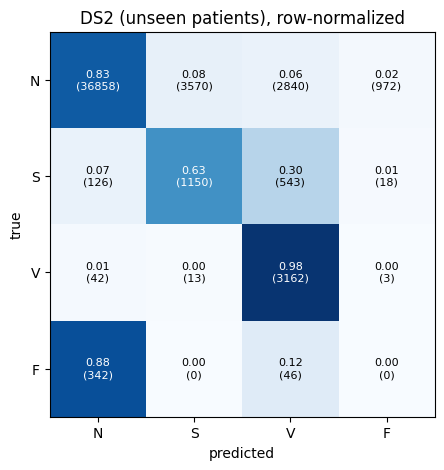

In [18]:
import matplotlib.pyplot as plt
cm = confusion_matrix(y2_i, pred_final, labels=[0,1,2,3])
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(C4); ax.set_yticks(range(4)); ax.set_yticklabels(C4)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("DS2 (unseen patients), row-normalized")
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cmn[i,j]:.2f}\n({cm[i,j]})", ha="center", va="center", fontsize=8,
                color="white" if cmn[i,j] > .5 else "black")
plt.savefig(f"{SAVE}/confusion_matrix.png", dpi=200, bbox_inches="tight"); plt.show()

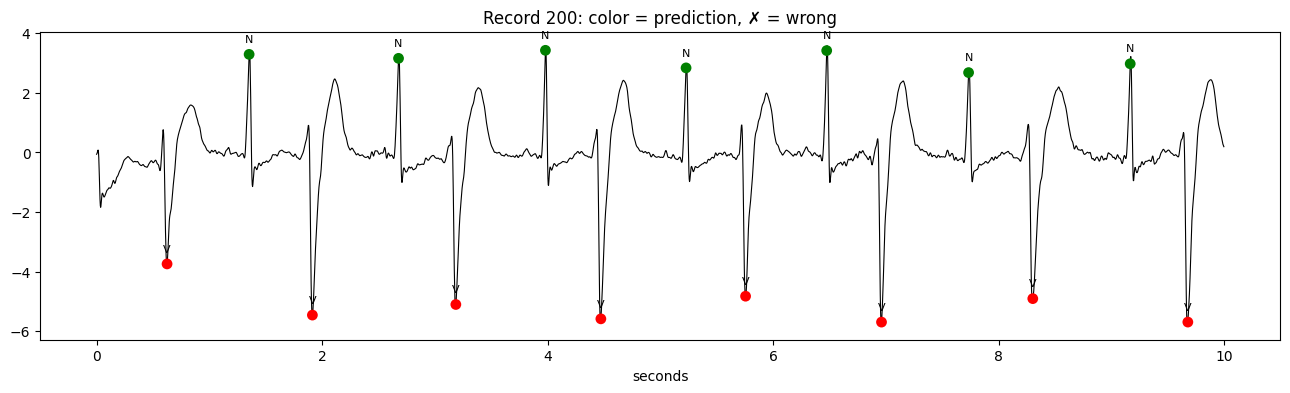

In [20]:
REC = "200"      # also try 214, 233, 221
sig = get_signal(REC)
m = id2_ == REC
pk, tr_, pr_ = pk2_[m], np.array(C4)[y2_i[m]], np.array(C4)[pred_final[m]]
i0 = np.argmax(tr_ != "N"); s0 = max(0, pk[i0] - 1800); s1 = s0 + 3600
col = {"N": "green", "S": "orange", "V": "red", "F": "purple"}
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(np.arange(s0, s1) / 360, sig[s0:s1], color="k", lw=0.8)
for p, t, q in zip(pk, tr_, pr_):
    if s0 <= p < s1:
        ax.scatter(p/360, sig[p], c=col[q], s=60, zorder=3, edgecolors="black" if q != t else "none")
        ax.text(p/360, sig[p] + 0.4, q + ("" if q == t else " ✗"), ha="center", fontsize=8)
ax.set_xlabel("seconds"); ax.set_title(f"Record {REC}: color = prediction, ✗ = wrong")
plt.savefig(f"{SAVE}/ecg_strip.png", dpi=200, bbox_inches="tight"); plt.show()

In [21]:
f1_nr = []
for seed in [0, 1, 2]:
    z1, z2 = np.zeros((len(y1_i), 1)), np.zeros((len(y2_i), 1))
    m, nrm = train_cnn(XA, z1, y1_i, BEST, seed)
    f1_nr.append(f1_score(y2_i, predict(m, XB, nrm(z2)), average="macro"))
print(f"CNN without RR: macro F1 {np.mean(f1_nr):.3f} ± {np.std(f1_nr):.3f}")

CNN without RR: macro F1 0.430 ± 0.031


In [16]:
s = df[df.true == 1].assign(hit=lambda d: d.pred == 1).groupby("rec").hit.agg(["mean", "size"])
print(s.round(2))
rest = s.drop("232")
print("S recall excluding 232:", round((rest["mean"] * rest["size"]).sum() / rest["size"].sum(), 3))

     mean  size
rec            
100  1.00    33
103  0.50     2
113  1.00     6
117  1.00     1
121  1.00     1
200  0.10    30
202  0.85    55
210  0.05    22
213  0.00    28
219  0.14     7
222  0.74   209
228  0.33     3
231  0.00     1
232  0.70  1382
233  0.00     7
234  0.00    50
S recall excluding 232: 0.549
